# Resonantly phase-matched 4WM JTWPA (QPDK JosephsonCircuits notebook, twpa-sim `jtwpa4wm`), rebuilt in the Quantcore PDK

**What it is.** A Josephson travelling-wave parametric amplifier: a transmission line made of a long series chain
of junctions with capacitance to ground. A strong pump raises the junction inductance (Kerr), the signal at f_s
mixes with the pump into an idler at 2 f_p − f_s and grows along the line (four-wave mixing). The Kerr shift
leaves the uniform chain phase-mismatched; LC resonators on every few cells, tuned just above the pump, restore
the phase matching (O'Brien et al., PRL 113, 157001 (2014); Macklin et al., Science 350, 307 (2015)).

**Sources.**
* Circuit: QPDK notebook `josephsoncircuits_twpa` (MIT; the JosephsonCircuits.jl example of Peng et al. 2022): 2047
  junctions, I_c 3.4 µA, C_J 55 fF, C_g 45 fF per cell (halved at the ends); every 4th cell 30 fF of C_g becomes a
  30 fF coupling capacitor to a 2.8153 pF ∥ 170 pH resonator (7.275 GHz); pump 3.7 µA peak Norton (≈ 1.85 µA in
  the chain) at 7.12 GHz; reported ≈ 25 dB (loaded) vs ≈ 5 dB (uniform) at 5 GHz.
* Layout family: twpa-sim `jtwpa4wm` (MIT): a series JJ chain with shunt capacitors, half shunts at both ends,
  60 µm cell pitch (`examples/layout/jtwpa4wm.json`, 8 cells).

Both cloned read-only into `build/external/` (never run).

| | source | Quantcore rebuild (why) |
|---|---|---|
| chain | 2047 cells (circuit) / 8 cells (twpa-sim layout) | a **shortened** 64-cell chain on the die (`JtwpaChain`, unit cell parameterised); the full 2047-cell circuit stays in the analysis |
| junction | I_c 3.4 µA, C_J 55 fF | the **largest PDK trilayer junction** (2 × 2 µm, I_c 0.65 µA, L_J 0.51 nH, C_J 200 fF); flagged `pdk_rn`; both the drawn and the source values are simulated |
| shunt C_g | 45 fF (MIM in twpa-sim) | interdigital fingers island–ground per cell (analytic estimate) |
| resonators | 2.8 pF ∥ 170 pH every 4th cell (lumped, ideal) | a pad + meander inductor + coupling IDC beyond the trench wall, every 4th node, alternating sides (drawn values are much smaller: tabulated) |
| chip | — | 7.5 × 7.5 mm PDK die, input / output `BondPad`s 100 µm from the edge |

**How this notebook goes.** First the **Design**: the chip is laid out one segment at a time, each segment its own
cell with a picture of the chip so far — the 7.5 mm die, the input and output bond pads, the feed lines (none of their
own: signal and pump share the two feeds, which end on the chain), the 64-junction chain with its loading resonators,
the two 50 Ω feeds, and then the whole chip (the sim group, the save). Then the same steps as the Flow strip of the
Quantcore KLayout plugin: **Check** (DRC, netlist) → **LOM** (the amplifier's circuit models, their plots, one change
by hand) → **Simulate** (export to HFSS and the chain's Q3D C-matrix; no eigenmode or full-wave run of a 64-cell line,
said why) → **Results** (the Q3D capacitances plotted and read, against the LOM, a feedback step and the iteration to
an impedance target) → **Fab**.

**Nothing here solves on its own.** The switches (the code cell after Setup) are off (`RUN_FEM = False`): FEM results
are loaded when a solve has been kept, otherwise each FEM cell says what would appear. The notebook before this
rewrite (the layout in four cells, with its outputs) is kept as `jtwpa_4wm.v1.ipynb`; both save the same
`jtwpa_4wm.json`. The v1 notebook saves the file twice, the second time after its by-hand change has written
`inductor_turns: 10` (the cell's default) into the chain's parameters; here that value is in the layout call, and the
by-hand change (LOM 3) works on a copy.

## Setup

The imports, the output folder and the switches. `_amplifiers` holds the amplifier notebooks' helpers (the PDK
facts, value tables, plots, the linear S-parameters of a LOM netlist, and the readers that put kept FEM results in
amplifier terms); `_common` the helpers all design notebooks share (tables, snapshots, the PDK placement, the FEM and
feedback steps). The physics is `quantcore_circuits.analysis.amplifiers`, the cells
`quantcore_circuits.layouts.others.amplifiers`.

`LIVE`: with KLayout open (the default) every change below is pushed to the KLayout window as you run it; with
`QCC_LIVE=0` the notebook builds headless and only writes files.

**The switches** (next cell): `RUN_FEM` solves the FEM jobs in AEDT 2024 R1 or newer, one after the other (a new
non-graphical AEDT unless `AEDT_MODE` says otherwise; an AEDT you have open is never touched); `RESOLVE` solves again
even when kept results match; `FEM_FAST` exports with the library's fast test settings (minutes, values not
converged); `MAX_ITER` caps the feedback iterations towards the targets.

In [2]:
import os, sys
from pathlib import Path
import numpy as np
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "pyproject.toml").exists())
os.chdir(ROOT)
sys.path.insert(0, str(ROOT / "examples" / "designs"))
sys.path.insert(0, str(ROOT / "examples" / "designs" / "amplifiers"))
from _common import *
from _amplifiers import pdk_facts_md, plot, show_md, table_md, lom_sparams
from _amplifiers import cmatrix_between, cmatrix_to_ground   # v2: kept FEM results in amplifier terms (Results)
from quantcore_circuits.designer import Designer
from quantcore_circuits.pdk import get_pdk
from quantcore_circuits.analysis import amplifiers as amp
from quantcore_circuits.layouts.others.amplifiers import JtwpaChain, drawn_junction_values
from quantcore_circuits.circuit.bridges import rn_from_lj

LIVE = os.environ.get("QCC_LIVE", "1") == "1"
OUT = Path("examples/designs/amplifiers")
PDK = get_pdk()

In [3]:
RUN_FEM = False        # True (or a set such as {"q3d_cmatrix"}): solve the FEM jobs in AEDT 2024 R1+, one at a time
RESOLVE = False        # True (or a set of analyses): solve again even when kept results match
FEM_FAST = True        # True: the library's fast test settings (minutes, not converged); False: the settings as written
AEDT_MODE = "batch"    # "batch" (no window) | "gui" (a new AEDT window, left open) | "attach" (the AEDT you have open)
MAX_ITER = 3           # feedback iterations towards the targets (Results 5)

## The Quantcore PDK this chip uses

The rebuild takes every process fact from the PDK (`get_pdk()`), not from the source: the stack the LOM and the FEM
jobs use, the die frame, where pads go, which junction is drawn, the film's kinetic inductance, the cheese and the 3/0
keep-outs. For this chip that means: the 7.5 mm die with the QCT frame, the two bond pads 100 µm from the west and
east edges, and the largest junction the PDK finger range allows (a 2 × 2 µm trilayer). A TWPA junction must carry far
more current than a qubit's, so it sits far outside the qubit R_n window: flagged `pdk_rn`, not retuned.

In [4]:
show_md(pdk_facts_md(PDK))

| PDK | value |
|---|---|
| substrate | sapphire 650 µm, εr 10.25 |
| film | Nb 200 nm, λ_L 90 nm → L_s 0.116 pH/□ (kinetic, in every CPW / wire formula) |
| junction rule | Nb/AlOx/Nb trilayer, Δ 1.4 meV, J_c 0.163 µA/µm², R_n window 40–50 kΩ, fingers 0.1–2 µm |
| frame | die 7.5 × 7.5 mm standard, margin 100 µm, marker areas 500 µm, brand QCT |
| pad rule | outer etch 100 µm (one dicing-marker width) from the die edge (`edge="auto"`) |
| cheese | PDK band 3 rows of 5 µm squares, 20 µm gap, around the 3/0 keep-outs (unless the original has its own) |
| 3/0 keep-out | routes + 10 µm, components + 24 µm |

# Design: the layout, one segment at a time

An amplifier chip is laid out the way a designer would do it by hand: the die, the bond pads, the feed (and pump)
line, the nonlinear element, the routing, and then the whole chip. Each segment is one cell with one picture of the
chip so far (and, live, KLayout redraws after every cell). A route always joins two ports, so a line is drawn once
both of its ends exist. The line under each picture counts what is on the chip; it says 0 qubits: an amplifier has
none, its junctions sit inside the amplifier cell (counted among the other components).

| segment | what is placed here |
|---|---|
| 1 | the 7.5 × 7.5 mm die with the QCT frame |
| 2 | the input and output `BondPad`s on the west and east edges, on the chain's axis |
| 3 | the feed lines: none of their own (signal and pump share the two feeds, which end on the chain: Design 5) |
| 4 | the nonlinear element: the junction (drawn against the source's), then the 64-junction `JtwpaChain` with a resonator on every 4th node |
| 5 | the routing: the two straight 50 Ω feeds, pad → chain → pad |
| 6 | the whole chip: the sim group, the save |

## Design 1 · The die and its frame

`Designer(name, box=...)` opens an empty chip: a standard 7.5 × 7.5 mm Quantcore die, on which the PDK draws the
**QCT frame** — the L dicing markers in the corners, the alignment grids in the corner marker areas, the chip boundary
and the device ID (`name_chip` "JTWPA") on a free edge. `YC` is the die's mid-height: the chain and its feeds run
along it.

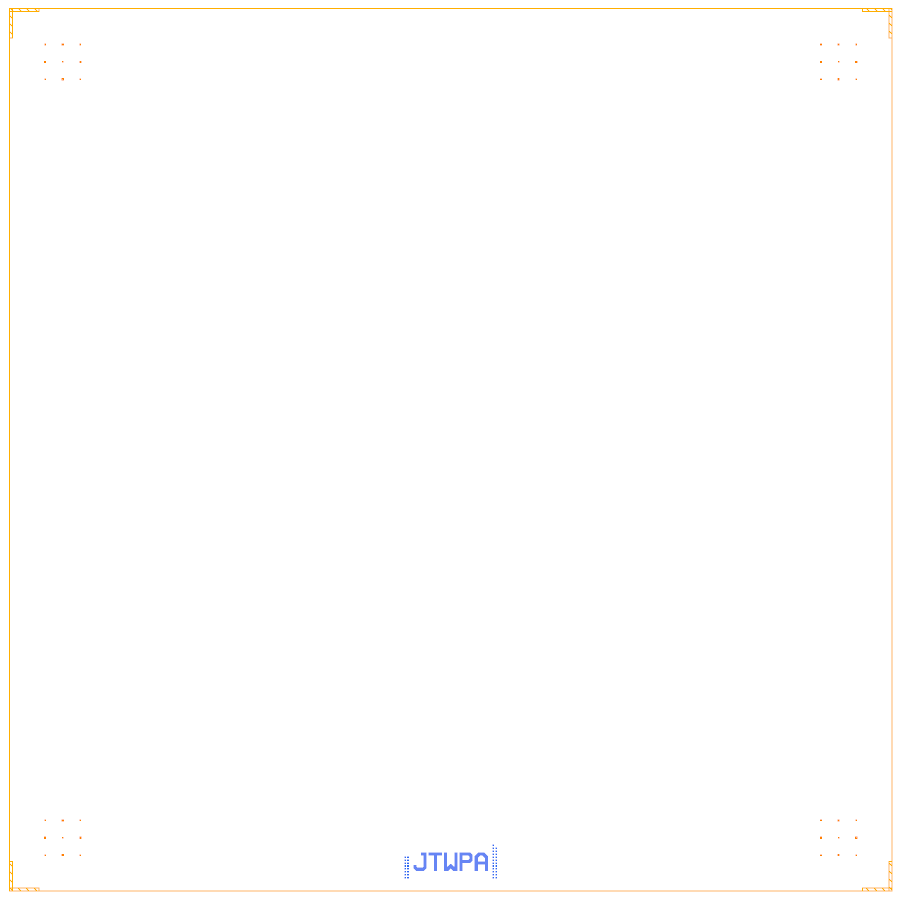

**On the chip so far:** 0 pads · 0 qubits · 0 other components · 0 routes · 0 declared couplings. **This step added** nothing new to the layout.

WindowsPath('examples/designs/amplifiers/jtwpa_4wm_s1_die.png')

In [5]:
W = H = 7500
YC = 3750
d = Designer("jtwpa_4wm", box=(0, 0, W, H), chip={"name_chip": "JTWPA"}, live=LIVE)
layout_step(d, OUT / "jtwpa_4wm_s1_die.png", size=(900, 900), width=400)

## Design 2 · Bond pads (the 100 µm rule)
Input pad on the west edge, output pad on the east edge. `edge="auto"` slides each pad perpendicular to its die edge
until its outer etch is the PDK `pad_edge` (100 µm) from it. Signal and pump both come in through `P_IN` and leave
through `P_OUT`: a TWPA is a two-port line, so these two pads are all it needs.

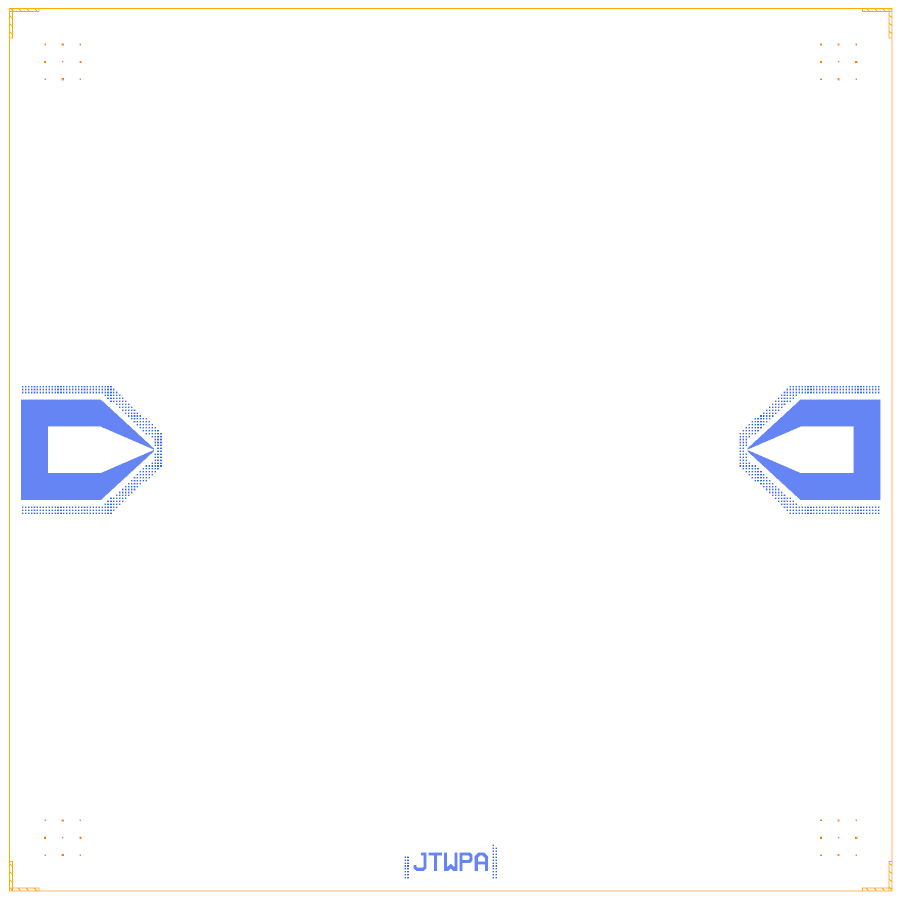

**On the chip so far:** 2 pads · 0 qubits · 0 other components · 0 routes · 0 declared couplings. **This step added** 2 component(s) `P_IN`, `P_OUT`.

WindowsPath('examples/designs/amplifiers/jtwpa_4wm_s2_pads.png')

In [6]:
with d.batch():
    d.add("P_IN", "BondPad", at=(400, YC), rot=-90, edge="auto")
    d.add("P_OUT", "BondPad", at=(7100, YC), rot=90, edge="auto")
layout_step(d, OUT / "jtwpa_4wm_s2_pads.png", size=(900, 900), width=400)

## Design 3 · The feed lines come with the chain

A TWPA is pumped through its signal port: the pump (7.12 GHz in the source) and the signal travel the same line, so
there is no separate pump line to place. The two 50 Ω feeds end on the chain's own ports (`JT.a`, `JT.b`), so they are
drawn in Design 5, once the chain is there. Nothing to place here.

## Design 4 · The nonlinear element: the junction chain

**The junction.** The source's junction (I_c 3.4 µA, C_J 55 fF) is beyond the PDK rule: the largest junction the PDK
finger range allows is a 2 × 2 µm trilayer (`BIG_JJ`). `drawn_junction_values` gives the drawn junction's L_J and C_J
from the PDK; the first table puts it next to the source's (the plasma frequency is the junction's own L_J–C_J
resonance, far above the band).

**The chain.** `JT` (`JtwpaChain`): 64 junctions at 60 µm pitch between 20 µm-wide islands cut by 12 µm gaps, each gap
bridged by the trilayer junction (window 18 × 12 µm). Each full island has 4 shunt fingers per side (40 µm long, 2/2
µm), interleaved with ground fingers from the trench walls (the end islands half as many: the half shunts). Every 4th
node (2, 6, 10, …) gets a resonator beyond the trench wall, alternating up and down: a lead through a slot in the 10
µm wall, a 10-finger coupling IDC, a 160 × 120 µm pad, a 10-turn meander inductor to the pocket ceiling.

`inductor_turns=10` is the meander's turn count as the design file has it (the cell's default; the v1 notebook wrote
it in its by-hand step, so it is in the layout call here and the saved file stays the same). The second table
compares the drawn unit cell's analytic values with the source circuit's. The first picture is the chip so far, the
second zooms on the first loaded unit (four cells and a resonator); the full-chip zooms are in Fab 2.

In [7]:
BIG_JJ = {"finger_width": 2.0, "second_finger_width": 2.0}
LJ, CJ, _ = drawn_junction_values("Quantcore Junction", BIG_JJ)
SRC = dict(ic=3.4e-6, cj=55e-15, cg=45e-15, cc=30e-15, lr=170e-12, cr=2.8153e-12, cells=2047, every=4,
           fp=7.12e9, ip=3.7e-6 / 2)
show_md(table_md(["junction", "I_c (µA)", "L_J (pH)", "C_J (fF)", "R_n (kΩ)", "plasma f (GHz)"], [
    ["drawn: trilayer 2.0 × 2.0 µm", amp.ic_from_lj(LJ * 1e-9) * 1e6, LJ * 1e3, CJ, rn_from_lj(LJ) / 1e3,
     1 / (2 * np.pi * np.sqrt(LJ * 1e-9 * CJ * 1e-15)) / 1e9],
    ["QPDK / JosephsonCircuits", 3.4, amp.lj_from_ic(SRC["ic"]) * 1e12, 55, rn_from_lj(amp.lj_from_ic(SRC["ic"]) * 1e9)
     / 1e3, 1 / (2 * np.pi * np.sqrt(amp.lj_from_ic(SRC["ic"]) * SRC["cj"])) / 1e9]]))

| junction | I_c (µA) | L_J (pH) | C_J (fF) | R_n (kΩ) | plasma f (GHz) |
|---|---|---|---|---|---|
| drawn: trilayer 2.0 × 2.0 µm | 0.6516 | 505.1 | 200 | 3.375 | 15.84 |
| QPDK / JosephsonCircuits | 3.4 | 96.8 | 55 | 0.6468 | 68.98 |

| per cell | drawn (analytic) | source |
|---|---|---|
| L_J (pH) | 505.1 | 96.8 |
| C_J (fF) | 200 | 55 |
| C_g (fF) | 31.95 | 45 |
| C_g on a loaded node (fF) | 15.97 | 15 |
| C_c (fF) | 17.87 | 30 |
| C_r (fF) | 72.18 | 2815 |
| L_r (nH, incl. kinetic) | 2.769 | 0.17 |
| resonator f (GHz) | 10.08 | 7.275 |
| Z = √(L_J/C_g) (Ω) | 125.7 | 46.38 |

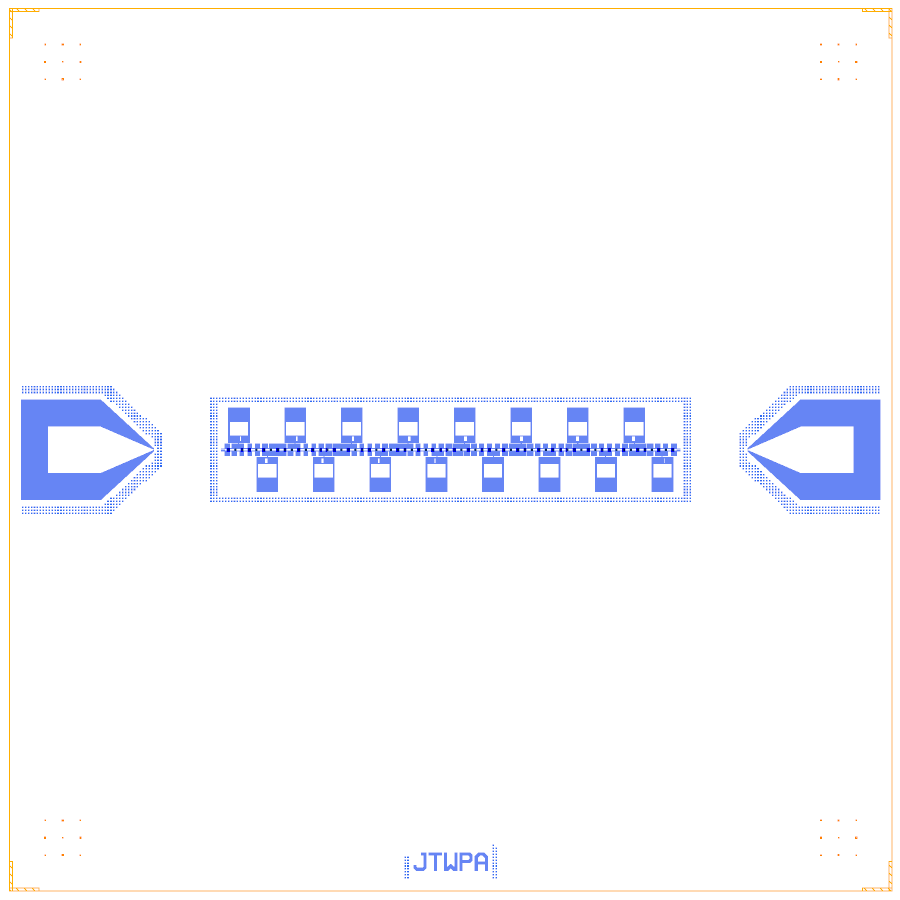

**On the chip so far:** 2 pads · 0 qubits · 1 other components · 0 routes · 0 declared couplings. **This step added** 1 component(s) `JT`.

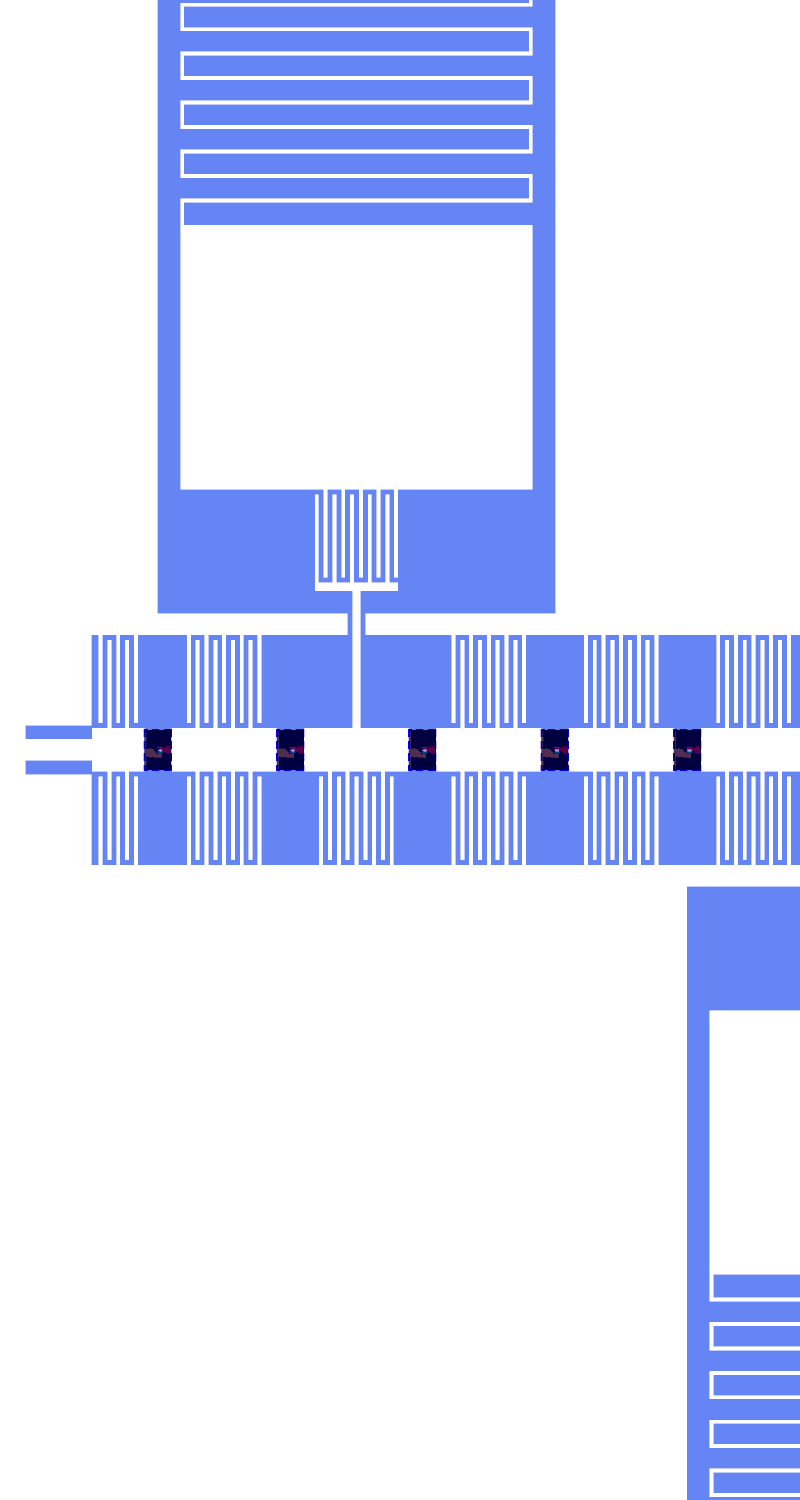

WindowsPath('examples/designs/amplifiers/jtwpa_4wm_s4_unit.png')

In [8]:
CHAIN = dict(cells=64, cell_pitch=60, junction_params=BIG_JJ, resonator_every=4, resonator_offset=2,
             inductor_turns=10)
with d.batch():
    jt = d.add("JT", "JtwpaChain", at=(3750 - (2 * 30 + 64 * 60) / 2, YC), junction={"Lj_nH": LJ, "Cj_fF": CJ},
               **CHAIN)
V = JtwpaChain.qcc_values(jt.spec["params"])
f_rd = 1 / (2 * np.pi * np.sqrt(V["Lr_nH"] * 1e-9 * (V["Cr_fF"] + V["Cc_fF"]) * 1e-15)) / 1e9
show_md(table_md(["per cell", "drawn (analytic)", "source"], [
    ["L_J (pH)", LJ * 1e3, amp.lj_from_ic(SRC["ic"]) * 1e12], ["C_J (fF)", CJ, 55],
    ["C_g (fF)", V["Cg_fF"], 45], ["C_g on a loaded node (fF)", V["Cg_loaded_fF"], 15],
    ["C_c (fF)", V["Cc_fF"], 30], ["C_r (fF)", V["Cr_fF"], 2815.3],
    ["L_r (nH, incl. kinetic)", V["Lr_nH"], 0.170], ["resonator f (GHz)", f_rd, 7.275],
    ["Z = √(L_J/C_g) (Ω)", np.sqrt(LJ * 1e-9 / (V["Cg_fF"] * 1e-15)), np.sqrt(amp.lj_from_ic(SRC["ic"]) / SRC["cg"])]]))
layout_step(d, OUT / "jtwpa_4wm_s4_chain.png", size=(900, 900), width=400)
xa, ya = port_xy(d, "JT.a")                      # the chain's input port: the first loaded unit is next to it
snap(d, OUT / "jtwpa_4wm_s4_unit.png", box=(xa + 20, ya - 340, xa + 320, ya + 340), size=(800, 1500), width=300)

## Design 5 · Routing: the two feeds
Straight 50 Ω feeds from the pads to the chain ports. `L_IN` runs `P_IN.a` → `JT.a`, `L_OUT` `JT.b` → `P_OUT.a`, in
the PDK's 10/6 µm CPW: pad, chain and pad sit on one axis, so neither feed has a bend or a meander.

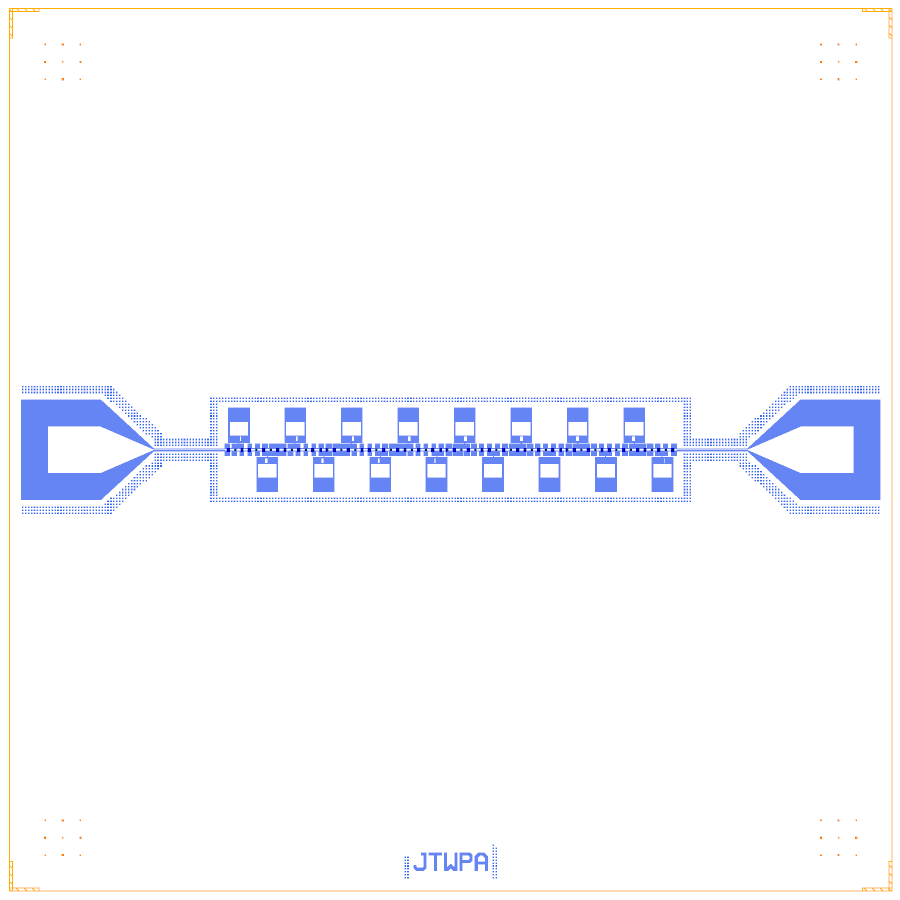

**On the chip so far:** 2 pads · 0 qubits · 1 other components · 2 routes · 0 declared couplings. **This step added** 2 route(s) `L_IN`, `L_OUT`.

WindowsPath('examples/designs/amplifiers/jtwpa_4wm_s5_feeds.png')

In [9]:
with d.batch():
    d.route("L_IN", "P_IN.a", "JT.a")
    d.route("L_OUT", "JT.b", "P_OUT.a")
layout_step(d, OUT / "jtwpa_4wm_s5_feeds.png", size=(900, 900), width=400)

## Design 6 · The whole chip: the sim group, the save

**Sim group.** `chain` says what a FEM job cuts out of the chip: the chain alone with a 60 µm margin, for a Q3D
C-matrix (the islands' capacitance to ground and to each other; the junctions are `Sim` gaps); the feeds are cut at
the box edge. The design sets no targets (Results 4 puts one on a copy).

**No centring.** The chain sits on the die centre and the pads on its axis, so the content is centred as drawn
(Check 1's `pdk_report` measures it).

**Save.** The JSON is the deliverable. `save_design` writes `jtwpa_4wm.json` and compares it with the file it replaces
(the previous run's, e.g. the `.v1` notebook's): the segments changed how the chip is built, not the chip, so it
should say *same design*. The picture is the whole chip.

**Same design as before:** `examples/designs/amplifiers/jtwpa_4wm.json` is identical to the file it replaces (byte for byte). The segments changed how the chip is built, not the chip.

<Designer jtwpa_4wm: 3 instances, 2 routes, live=False> → examples\designs\amplifiers\jtwpa_4wm.json


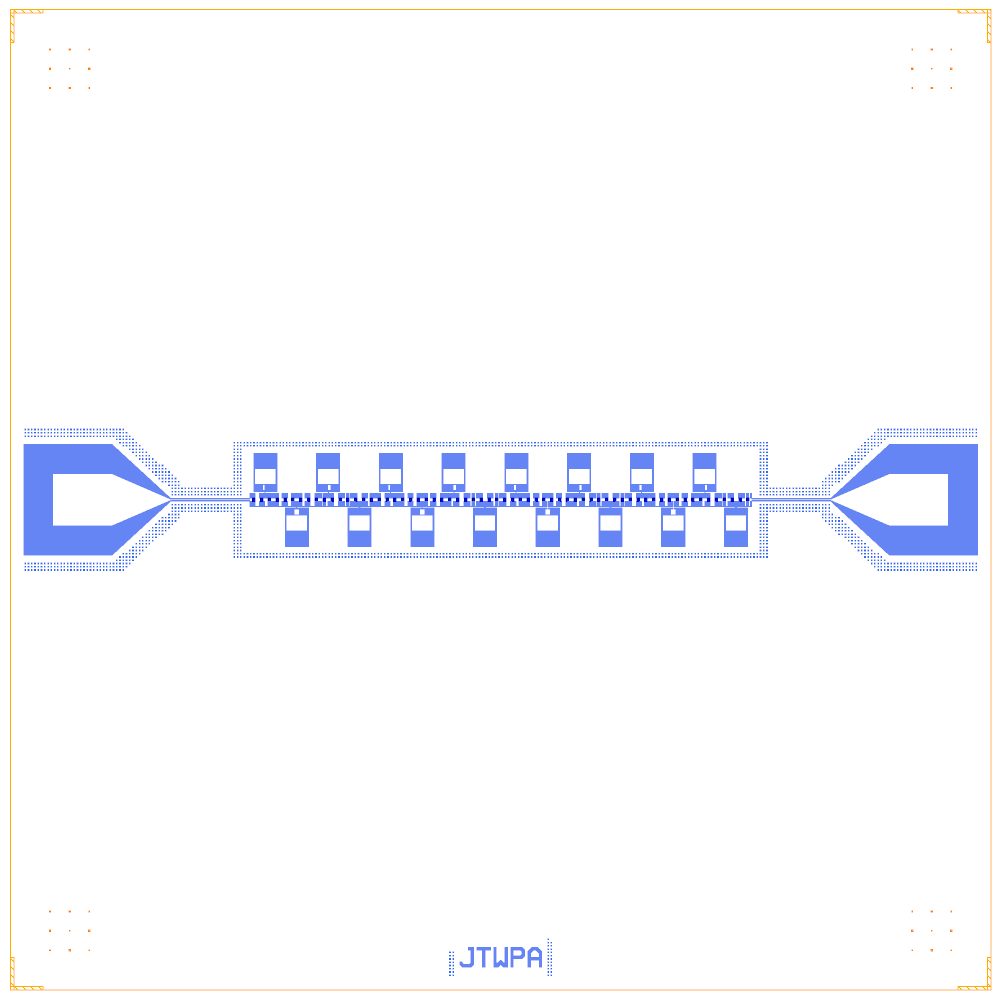

**On the chip so far:** 2 pads · 0 qubits · 1 other components · 2 routes · 0 declared couplings. **This step added** nothing new to the layout.

WindowsPath('examples/designs/amplifiers/jtwpa_4wm_s6_chip.png')

In [10]:
d.sim_group("chain", ["JT"], margin_um=60, analyses=["q3d_cmatrix"])
if not LIVE:
    d.show()
DESIGN, same = save_design(d, OUT / "jtwpa_4wm.json")
display(Markdown(same))
print(d, "→", DESIGN)
layout_step(d, OUT / "jtwpa_4wm_s6_chip.png", size=(1000, 1000), width=480)

# Check: DRC and netlist

The plugin's *Check* step: the design rules, then the lumped circuit the layout turns into.

## Check 1 · DRC
`pdk_rn` flags the chain junction (R_n ≈ 3.4 kΩ): a TWPA junction must be large.

Expected here (from the v1 run): **DRC clean** and one PDK design warning, `pdk_rn` on `JT` (L_J 0.505 nH, R_n ≈ 3.4
kΩ against the 40–50 kΩ qubit window); content centre − die centre (+0, +0) µm.

`d.drc()` checks connectivity (every port routed or snapped, route ends resolved), crossings, overlaps, the chip box
and the frame: **errors** would block fab, **warnings** are layout hints, **PDK design warnings** (`pad_edge`,
`pdk_rn`, …) flag a PDK margin and are never fixed by retuning. `pdk_report(d)` sums up the PDK side.

In [ ]:
print(d.drc())
show_md(pdk_report(d))

## Check 2 · Netlist
`JtwpaChain`'s model: 65 island nodes `JT.n0` … `JT.n64` (n0 / n64 joined to the pads by the feeds), a JJ between
neighbours, C_g to ground on each node, and per resonator a node `JT.r<k>` with C_c, C_r, L_r. 64 junctions are
far beyond QuCat's normal-mode solver (a few junctions), so the netlist is simulated linearly (LOM 1).

In [ ]:
lb = d.lom()
m = lb.model
show_md(f"**{len(m.nodes) - 1} nodes, {len(m.branches)} branches** "
        f"({sum(b.type == 'JJ' for b in m.branches.values())} JJ, {sum(b.type == 'L' for b in m.branches.values())} L)")
show_md(table_md(["branch", "type", "nodes", "value"], [
    [n, b.type, " – ".join(b.nodes), b.value.get("Lj_nH", b.value.get("L_nH", b.value.get("estimate")))]
    for n, b in list(m.branches.items())[:12]]) + "\n\n… (first 12 branches)")

# LOM: simulate the lumped circuit, and plot it

## LOM 1 · The circuit models

Three models of the chain, from the netlist above and from `analysis.amplifiers` (the ABCD ladder and the coupled-mode
gain); their plots are in LOM 2.

**(a) The drawn chain, linear** (`lom_sparams`: nodal analysis of the LOM netlist, junctions as L_J ∥ C_J):
transmission of the 64-cell die between the 50 Ω pads, and the Bloch dispersion of its 4-cell unit.

In [ ]:
f = np.linspace(1e9, 20e9, 1901)
port_nodes = [lb.port_map["P_IN.a"], lb.port_map["P_OUT.a"]]
S = lom_sparams(m, f, port_nodes)
cg, cgl = V["Cg_fF"] * 1e-15, V["Cg_loaded_fF"] * 1e-15
unit_d = amp.jtwpa_unit(f, LJ * 1e-9, CJ * 1e-15, cg, 4, (V["Cc_fF"] * 1e-15, V["Lr_nH"] * 1e-9, V["Cr_fF"] * 1e-15),
                        cgl)

**(b) The source circuit, 2047 cells** (QPDK values): Bloch phase per junction of the uniform and the loaded
chain, the cold mismatch 2q_p − q_s − q_i, and the 4WM coupled-mode gain with the pump at 7.12 GHz and
I_p = 1.85 µA ((I_p/I_c)² = 0.296), `analysis.amplifiers.cme_gain` (undepleted pump; ξ = 1/(2 I_c²)).

In [ ]:
lj_s = amp.lj_from_ic(SRC["ic"])
res_s = (SRC["cc"], SRC["lr"], SRC["cr"])

def q_src(freq, loaded):
    u = amp.jtwpa_unit(np.atleast_1d(freq), lj_s, SRC["cj"], SRC["cg"], 4 if loaded else 0,
                       res_s if loaded else None, SRC["cg"] - SRC["cc"])
    return amp.bloch(u).imag / (4 if loaded else 1)

fs = np.linspace(3e9, 11.2e9, 661)
fs = fs[np.abs(fs - SRC["fp"]) > 0.02e9]
GAIN = {}
for loaded in (False, True):
    kp = float(q_src(SRC["fp"], loaded)[0])
    g, dbeta, _ = amp.cme_gain(q_src(fs, loaded), q_src(2 * SRC["fp"] - fs, loaded), kp, SRC["cells"], SRC["ip"],
                               xi=1 / (2 * SRC["ic"] ** 2))
    GAIN["loaded" if loaded else "uniform"] = (amp.db(g), dbeta)
i5 = int(np.argmin(np.abs(fs - 5e9)))
show_md(table_md(["chain", "G at 5 GHz (dB)", "Δβ at 5 GHz (rad/junction)", "QPDK harmonic balance (dB)"], [
    ["uniform", GAIN["uniform"][0][i5], GAIN["uniform"][1][i5], "≈ 5"],
    ["loaded", GAIN["loaded"][0][i5], GAIN["loaded"][1][i5], "≈ 25"]]))

**(c) The drawn unit cell as a TWPA**: the same coupled-mode model with the drawn values, the chain extended to
2047 cells and the pump scaled to the same (I_p/I_c)² = 0.296 (I_p ≈ 0.35 µA). The drawn line is far from 50 Ω
(L_J/C_g, tabulated above) and its resonators sit far from the pump, so it is not phase-matched as drawn: the
numbers say what the PDK cell would need (larger C_g, larger resonator C) rather than predict a device.

In [ ]:
ic_d = amp.ic_from_lj(LJ * 1e-9)
def q_drawn(freq):
    return amp.bloch(amp.jtwpa_unit(np.atleast_1d(freq), LJ * 1e-9, CJ * 1e-15, cg, 4,
                                    (V["Cc_fF"] * 1e-15, V["Lr_nH"] * 1e-9, V["Cr_fF"] * 1e-15), cgl)).imag / 4
kp = float(q_drawn(SRC["fp"])[0])
gd, _, _g = amp.cme_gain(q_drawn(fs), q_drawn(2 * SRC["fp"] - fs), kp, 2047, np.sqrt(0.296) * ic_d,
                        xi=1 / (2 * ic_d**2))
show_md(f"Drawn cell: q_p = {kp:.3f} rad/junction at 7.12 GHz (source {float(q_src(SRC['fp'], True)[0]):.3f}); "
        f"G at 5 GHz ≈ {amp.db(gd)[i5]:.1f} dB for 2047 cells (Δβ = {float(_[i5]):+.4f} rad/junction: not phase "
        "matched; spikes in G next to the drawn resonator's stop band are outside this model's validity).")

## LOM 2 · The models in plots

Three plots: the drawn chain's |S21| and |S11| between the 50 Ω pads (model (a), linear, no pump): the pass band, and
the dip of the drawn resonators (it moves with L_r, LOM 3); the drawn unit's Bloch phase and attenuation per junction
(model (a)), the dispersion the phase matching works with; the source circuit's 4WM gain, uniform against loaded, the
pump marked (model (b)).

In [ ]:
with np.errstate(divide="ignore"):              # |S21| is exactly 0 at a few frequencies (log10 of 0)
    plot(OUT / "jtwpa_4wm_s21.png", [(f / 1e9, 20 * np.log10(np.abs(S[:, 1, 0])), "|S21| drawn 64-cell chain (LOM)"),
                                      (f / 1e9, 20 * np.log10(np.abs(S[:, 0, 0])), "|S11|", "--")],
         "frequency (GHz)", "dB", "drawn chain, linear response (no pump)", ylim=(-40, 2))
q_unit = amp.bloch(unit_d)                       # the drawn loaded unit (4 junctions, one resonator)
plot(OUT / "jtwpa_4wm_dispersion.png", [(f / 1e9, amp.unwrap_bloch(q_unit.imag) / 4, "Bloch phase (rad / junction)"),
                                         (f / 1e9, q_unit.real / 4, "attenuation (Np / junction)", "--")],
     "frequency (GHz)", "per junction", "drawn unit cell: dispersion (linear, no pump)")
plot(OUT / "jtwpa_4wm_gain.png", [(fs / 1e9, GAIN["uniform"][0], "uniform 2047-cell chain"),
                                   (fs / 1e9, GAIN["loaded"][0], "resonator every 4th cell")],
     "signal frequency (GHz)", "signal gain (dB)", "QPDK JTWPA circuit: 4WM coupled-mode gain, pump 7.12 GHz",
     vline=SRC["fp"] / 1e9);

## LOM 3 · One change by hand: the loading resonator
Before the FEM, a design step by hand. One property: the meander inductor 10 → 20 turns (longer wire: larger L_r,
lower resonator frequency). The change is made on a copy (`design_copy`: a non-live Designer that never writes over
the design file), so the chip saved in Design 6 stays as it is and nothing is saved again. From the v1 run: L_r 2.77 →
5.77 nH, f_r 10.08 → 6.98 GHz.

In [ ]:
V20 = JtwpaChain.qcc_values({**jt.spec["params"], "inductor_turns": 20})
rows = []
for turns, v in ((10, V), (20, V20)):
    rows.append([turns, v["inductor_length_um"], v["Lr_nH"], 1e3 * v["Lr_k_nH"],
                 1 / (2 * np.pi * np.sqrt(v["Lr_nH"] * 1e-9 * (v["Cr_fF"] + v["Cc_fF"]) * 1e-15)) / 1e9])
show_md(table_md(["turns", "wire (µm)", "L_r (nH)", "kinetic (pH)", "f_r (GHz)"], rows))
d2 = design_copy(DESIGN)                         # a non-live copy of the saved design (never saved over it)
d2["JT"].set(inductor_turns=20)
S20 = lom_sparams(d2.lom().model, f, port_nodes)
with np.errstate(divide="ignore"):
    plot(OUT / "jtwpa_4wm_iterate.png", [(f / 1e9, 20 * np.log10(np.abs(S[:, 1, 0])), "10 turns"),
                                          (f / 1e9, 20 * np.log10(np.abs(S20[:, 1, 0])), "20 turns")],
         "frequency (GHz)", "|S21| (dB)", "drawn chain: the resonator stop band moves with L_r", ylim=(-40, 2))

> **Simulation PC (32 GB+ RAM).** The cells below solve FEM jobs in AEDT. On this notebook's chip they need the
> simulation PC: set `RUN_FEM = True` and `FEM_FAST = False` there, run them one job at a time, and keep the results
> (`fem/`). On a smaller PC leave `RUN_FEM = False`: the cells export the jobs and load kept results only.

# Simulate: export to HFSS and the component simulation

The plugin's *Simulate* step. The LOM above uses analytic capacitance estimates; a finite-element job measures them.
Each job is a sim group cut out of the chip, written to `build/jobs/<design>_<group>_<analysis>/`. With `RUN_FEM =
False` (the default) the jobs are only exported: the cells load results that were solved and kept before (in
`examples/designs/amplifiers/fem/<job>/`), and otherwise say what would appear. Simulate 3–4 say why there is no
eigenmode or full-wave run here.

## Simulate 1 · Export to HFSS

A Q3D C-matrix job of the whole drawn chain: it measures the capacitances the LOM estimates (C_g of each island, C_c
of the couplers; the junctions are drawn as `Sim` gaps). `export_sims` cuts the `chain` group out of the chip (its
box, 60 µm round the chain), puts ports where the feeds leave the box and writes the job folder; simulation exports
never get cheese.

What the job can see (from the v1 run's job table): 65 nets — the 63 inner islands and the two feeds, which carry the
end islands `n0` / `n64` — and **no resonator-pad net**: each pad is tied to ground through its meander inductor, so
for a C-matrix it is ground. At a loaded island the matrix gives C_g and the coupling capacitor in one number, and C_r
is not measured (the v1 text said the job replaces the C_r estimate; its own job table shows it cannot).

`FEM_FAST` (the switch at the top) picks the fast test settings for every job exported from here on. With
`RUN_FEM = True` the next cells solve each Ansys job in a **new batch, non-graphical** AEDT 2024 R1 (or newer), so an
AEDT window you have open is never touched. The command-line equivalent is `qcc hfss solve build/jobs/<job>`.

In [ ]:
FEM_FAST = fem_fast(FEM_FAST)                    # the switch from the top: fast test settings, or as written
KEEP = fem_keep_dir(DESIGN)                      # examples/designs/amplifiers/fem/: solved results are kept here
jobs = export_sims(DESIGN, ["chain"])            # the chain's Q3D C-matrix job
display(Markdown(jobs_md(jobs)))

## Simulate 2 · Component simulation: the chain's Q3D C-matrix

`fem_stage` solves the job with `RUN_FEM`, else loads its kept results, else says that there are none. A 65-net
matrix is too big to print: the cell lists the first nets' capacitance to ground (the Maxwell row sums,
`cmatrix_to_ground`); Results 1–3 read the whole matrix.

In [ ]:
keep_q3d = fem_stage(jobs, RUN_FEM, KEEP, force=RESOLVE, aedt=AEDT_MODE)
display(Markdown(convergence_md({f"{g} · q3d": k for g, k in keep_q3d.items()})))
C_GND = cmatrix_to_ground(keep_q3d["chain"])     # {net: C to ground (fF)}; {} without results
if C_GND:
    show_md(table_md(["net", "C to ground (fF)"], [list(kv) for kv in list(C_GND.items())[:12]])
            + f"\n\n… (12 of {len(C_GND)} nets)")

## Simulate 3 · Eigenmode, and Simulate 4 · the full-wave run: not for a TWPA chain

The design has no eigenmode group, and a TWPA is not one resonance to read off: the 64-cell chain's modes are a band
of standing waves set by its two ends, and the device the analysis describes has 2047 cells. What a measurement of the
amplifier sees (the gain of the pumped line) needs the nonlinear models of LOM 1 in any case; the FEM's part is the
unit cell's capacitance (Simulate 2), which goes into the LOM netlist and the ABCD ladder (Results 3). No eigenmode or
driven job is exported.

# Results: plot, read the values, compare with the LOM, feed back, iterate

The plugin's *Results* step: what the FEM found, against the LOM and against a target, and the design change that
moves the chip towards the target.

## Results 1 · Plot the Q3D values

No eigenmodes to plot here (Simulate 3). What the FEM measured is plotted instead: each island's capacitance to ground
along the chain, the Q3D value against the LOM's estimate — C_g on a plain island, C_g + C_c on a loaded one (the
resonator pad is ground for the C-matrix, Simulate 1). The end islands are left out: they share a net with their
feed.

In [ ]:
RES_NODES = set(V["resonators"])                 # the loaded islands (a resonator on every 4th)
INNER = range(1, CHAIN["cells"])                 # n1 … n63 (n0 / n64 share a net with their feed)


def lom_c(k):
    """The LOM's capacitance to ground of island k as the C-matrix sees it (a loaded island with its C_c)."""
    return V["Cg_loaded_fF"] + V["Cc_fF"] if k in RES_NODES else V["Cg_fF"]


fem_c = {k: C_GND[f"JT.n{k}"] for k in INNER if f"JT.n{k}" in C_GND}
if fem_c:
    plot(OUT / "jtwpa_4wm_cmatrix.png", [(list(fem_c), [lom_c(k) for k in fem_c], "LOM estimate", "s--"),
                                          (list(fem_c), list(fem_c.values()), "Q3D (FEM)", "o")],
         "island k (net JT.n<k>)", "C to ground (fF)", "chain islands: capacitance to ground, LOM against FEM")
else:
    print("No Q3D results yet (RUN_FEM = True): this plot would show each island's capacitance to ground along the "
          "chain, FEM against the LOM's estimate (plain and loaded islands).")

## Results 2 · The values

The unit cell in the FEM's terms: the mean C_g of the plain islands, the loaded islands' C_g + C_c, the capacitance
between neighbouring islands across a junction gap (it adds to C_J; the LOM has the junction's C_J only), and the
line impedance Z = √(L_J / C_g) the matching depends on (50 Ω wanted).

In [ ]:
def z_line(cg_fF):
    """The chain's impedance √(L_J / C_g) with the drawn junction (Ω)."""
    return float(np.sqrt(LJ * 1e-9 / (cg_fF * 1e-15)))


fem_plain = [c for k, c in fem_c.items() if k not in RES_NODES]
fem_loaded = [c for k, c in fem_c.items() if k in RES_NODES]
gaps = [cmatrix_between(keep_q3d["chain"], f"JT.n{k}", f"JT.n{k + 1}") for k in range(1, CHAIN["cells"] - 1)]
gaps = [x for x in gaps if x is not None]
CG_FEM = float(np.mean(fem_plain)) if fem_plain else None      # mean C_g of the plain islands (FEM)
CL_FEM = float(np.mean(fem_loaded)) if fem_loaded else None    # mean C_g + C_c of the loaded islands (FEM)
CELL = {"C_g plain (fF)": (V["Cg_fF"], CG_FEM),
        "C_g + C_c loaded (fF)": (V["Cg_loaded_fF"] + V["Cc_fF"], CL_FEM),
        "C across a junction gap (fF)": (None, float(np.mean(gaps)) if gaps else None),
        "Z = √(L_J / C_g) (Ω)": (z_line(V["Cg_fF"]), z_line(CG_FEM) if CG_FEM else None)}
show_md(table_md(["per cell", "LOM (analytic)", "Q3D (FEM)"], [[k, a, b] for k, (a, b) in CELL.items()]))
if CG_FEM is None:
    print("No Q3D results yet: the FEM column fills with RUN_FEM = True (or kept results).")

## Results 3 · FEM against the LOM

The LOM's cell values next to the Q3D's, with the difference in %, and what the difference does to the line: the
drawn unit's Bloch phase at the pump frequency (7.12 GHz, the number the phase matching is built on), with C_g from
the LOM and from the FEM.

In [ ]:
def q_pump(cg_fF, cgl_fF):
    """Bloch phase per junction of the drawn loaded unit at the pump frequency (rad), for given C_g (plain, loaded)."""
    u = amp.jtwpa_unit(np.atleast_1d(SRC["fp"]), LJ * 1e-9, CJ * 1e-15, cg_fF * 1e-15, 4,
                       (V["Cc_fF"] * 1e-15, V["Lr_nH"] * 1e-9, V["Cr_fF"] * 1e-15), cgl_fF * 1e-15)
    return float(amp.bloch(u).imag[0]) / 4


cmp_rows = [(k, a, b, "Q3D C-matrix, mean over the chain") for k, (a, b) in CELL.items() if a and b is not None]
if CG_FEM:
    cgl_fem = CL_FEM - V["Cc_fF"] if CL_FEM else V["Cg_loaded_fF"]
    cmp_rows.append(("q_p at 7.12 GHz (rad / junction)", q_pump(V["Cg_fF"], V["Cg_loaded_fF"]),
                     q_pump(CG_FEM, cgl_fem), "drawn unit, ABCD, C_g from the Q3D"))
if cmp_rows:
    display(Markdown(fem_vs_lom_md(cmp_rows)))
else:
    print("No FEM results yet: with RUN_FEM = True this table puts the cell's C_g, C_g + C_c and Z from the LOM next "
          "to the Q3D's, with the difference in %, and the drawn unit's Bloch phase at the pump on both.")

## Results 4 · Feedback: one step towards a target

A TWPA must first of all be a 50 Ω line: at both ends it meets the 50 Ω feeds, and a mismatched chain reflects the
pump and the signal (ripples in the gain). The drawn cell is far from it (from the v1 run: Z = √(L_J / C_g) ≈ 126 Ω
with the analytic C_g of 32 fF; the v1 summary: a PDK-native cell needs C_g ≈ L_J / Z0² ≈ 0.2 pF). That is this
notebook's exercise target: **Z = 50 Ω ± 1 Ω**, on a copy (`target_copy` → `build/jtwpa_4wm_target.json`).

`loop.feedback` tunes qubit–readout pairs; a TWPA chain has none, so the feedback is the cell's first-order rule: Z ∝
C_g^−1/2 and C_g (the interdigital shunt) ∝ the finger overlap ℓ − gap, so Z ∝ ℓ^p with the prior p = −½ ℓ / (ℓ −
gap), on one knob, `JT.shunt_finger_length` (40 µm now). Six times the C_g means fingers ≈ 240 µm long by the rule: a
much wider trench, with the resonators beyond its walls. When a Q3D is kept, the LOM's C_g is first scaled by FEM /
LOM (`SCALE`), so the step aims at the FEM value. The resonators are not targeted: f_r depends on L_r, C_r and C_c,
not on C_g.

In [ ]:
from quantcore_circuits.layouts.others.keepout import full_params

Z_T, Z_TOL = 50.0, 1.0                           # the exercise target and its tolerance (Ω)
DESIGN_T = target_copy(DESIGN, {"JT": {"Z_ohm": Z_T}})
FP = full_params(JtwpaChain, jt.spec["params"])  # the chain's parameters, the cell defaults filled in
K0, GAP = float(FP["shunt_finger_length"]), float(FP["shunt_gap"])
SCALE = CG_FEM / V["Cg_fF"] if CG_FEM else 1.0   # FEM / LOM of C_g at the drawn fingers (1: the LOM alone)
Z_NOW = z_line(SCALE * V["Cg_fF"])
P0 = -0.5 * K0 / (K0 - GAP)                      # Z ∝ C_g^-1/2, C_g ∝ the finger overlap (length − gap)
K1 = rule_step(K0, Z_NOW, Z_T, P0)
show_md(f"**Z:** now {Z_NOW:.1f} Ω ({'FEM' if CG_FEM else 'LOM'} C_g {SCALE * V['Cg_fF']:.1f} fF), target {Z_T:g} ± "
        f"{Z_TOL:g} Ω → shunt fingers {K0:g} → **{K1:.1f} µm** (Z ∝ ℓ^{P0:.2f}); C_g wanted ≈ "
        f"{LJ * 1e-9 / Z_T ** 2 * 1e15:.0f} fF")

## Results 5 · Iterate to the target

The rule repeated (`rule_iterate`): revision k gets the finger length, its analytic C_g (× `SCALE`) gives Z, and the
next step uses the exponent of the last two points (a secant), until Z is within 1 Ω or `MAX_ITER` steps are made; the
finger length stays within 10–300 µm. Each revision is a design file (`build/jtwpa_4wm_rev<k>.json`). With
`RUN_FEM = True` each revision's `chain` Q3D is exported to `build/jobs/rev<k>/` and solved (a big job: 65 islands),
and the loop closes on the FEM's C_g. The table shows each step's Z against the target and the knob it moved; the plot
the residual in tolerances (on target below 1).

In [ ]:
def mean_plain_cg(keep):
    """Mean capacitance to ground of the plain inner islands of a kept chain Q3D job (fF); None without results."""
    c = cmatrix_to_ground(keep)
    vals = [c[f"JT.n{k}"] for k in INNER if k not in RES_NODES and f"JT.n{k}" in c]
    return float(np.mean(vals)) if vals else None


def z_of(k, it):
    """Revision it: shunt fingers k µm long; its Z from the analytic C_g (× SCALE), or from its own Q3D (RUN_FEM)."""
    d2 = design_copy(DESIGN_T, f"_rev{it}")
    d2["JT"].set(shunt_finger_length=k)
    path = d2.save(Path("build") / f"jtwpa_4wm_rev{it}.json")
    if RUN_FEM:
        job = export_sims(path, ["chain"], root=f"build/jobs/rev{it}")
        cg = mean_plain_cg(fem_stage(job, RUN_FEM, KEEP / f"rev{it}", force=RESOLVE, aedt=AEDT_MODE)["chain"])
        if cg:
            return z_line(cg), path
    return z_line(SCALE * JtwpaChain.qcc_values(d2["JT"].spec["params"])["Cg_fF"]), path


history = rule_iterate(z_of, "JT.Z_ohm", "JT.shunt_finger_length", K0, Z_T, Z_TOL, P0, max_iter=MAX_ITER,
                       start=(Z_NOW, DESIGN_T), fem=bool(RUN_FEM), bounds=(10.0, 300.0))
display(Markdown(history_md(history)))
plot_iterations(history, OUT / "jtwpa_4wm_feedback.png")
print("last design:", history[-1]["design"], "· on target:", history[-1]["on_target"])

# Fab: the mask, snapshots, summary

## Fab 1 · Build and export
The design JSON saved in Design 6 is the deliverable: `qcc build examples/designs/amplifiers/jtwpa_4wm.json`, `qcc
mask …` and the KLayout plugin read it. `export_fab` writes the PDK fab layers (negative mask, corner rounding, the
PDK cheese band).

In [ ]:
from quantcore_circuits.layouts.wafers.fab_export import export_fab
if d.result is None:
    d.show()
fab = {}
export_fab(d.result, Path("build") / f"{d.design.name}_fab.oas", report=fab)
show_md(f"cheese: {fab.get('cheese_source')}; written: " + ", ".join(f"{k} {n}" for k, n in fab["written"].items()))

## Fab 2 · Snapshots
The full die; one loaded unit (four cells and a resonator); one junction (trilayer window in the island cut).

In [ ]:
show_snapshot(d, OUT / "jtwpa_4wm.png", size=(1400, 1400))
x0, y0 = port_xy(d, "JT.a")
show_snapshot(d, OUT / "jtwpa_4wm_unit.png", box=(x0 + 20, y0 - 340, x0 + 320, y0 + 340), size=(800, 1500),
              width=360)
xj = x0 + 30 + 1.5 * 60
show_snapshot(d, OUT / "jtwpa_4wm_jj.png", box=(xj - 12, y0 - 12, xj + 12, y0 + 12), size=(900, 900), width=360)

## Summary
* **Matches the source:** a series junction chain with shunt capacitors and half shunts at both ends (twpa-sim),
  resonators on every 4th cell (QPDK / O'Brien); the 2047-cell source circuit is simulated (dispersion, cold mismatch,
  gain) and reproduces QPDK's trend (loaded ≫ uniform at 5 GHz; from the v1 run 21.3 against 6.2 dB, QPDK ≈ 25 against
  ≈ 5 dB).
* **Differs:** a 64-cell chain on the die; the PDK junction (0.65 µA, L_J 0.51 nH) instead of 3.4 µA; planar shunt and
  resonator capacitors whose drawn values (tabulated) are far below the source's 45 fF / 2.8 pF.
* **PDK design warnings:** `pdk_rn` on `JT`.
* **Open:** a PDK-native JTWPA needs C_g ≈ L_J/Z0² ≈ 0.2 pF per cell and pF-scale resonators (or a higher-J_c junction
  process, a PDK request); harmonic balance (JosephsonCircuits.jl) is not in
  this environment.
* **Layout:** built in six segments (die, pads, the chain, the two feeds, the whole chip; no separate pump line); the
  saved JSON is the v1 notebook's (`inductor_turns: 10` is now in the layout call).
* **Feedback:** an exercise target on a copy (Z = 50 Ω): a first-order rule on the shunt finger length (Z ∝ C_g^−1/2),
  iterated with a secant (analytic C_g × FEM/LOM; the revision's Q3D with `RUN_FEM`).
* **FEM:** the chain's Q3D job is exported, not solved (`RUN_FEM = False`): run with `RUN_FEM = True` to fill the
  Simulate and Results cells. No eigenmode or driven job (Simulate 3–4).